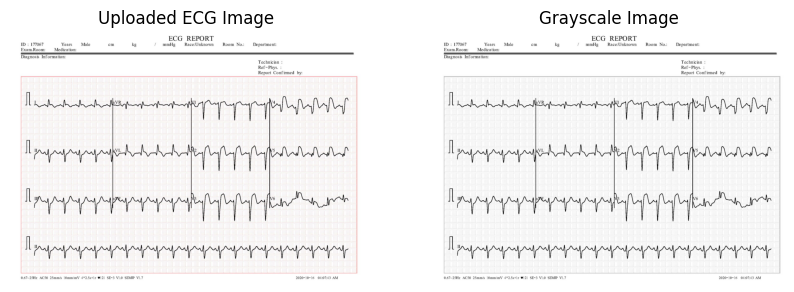

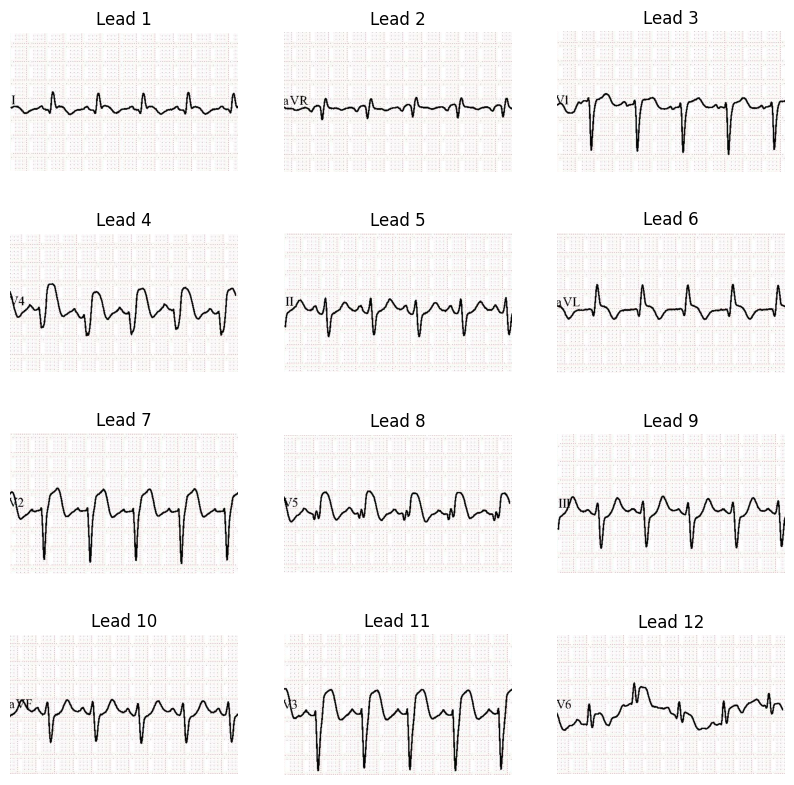

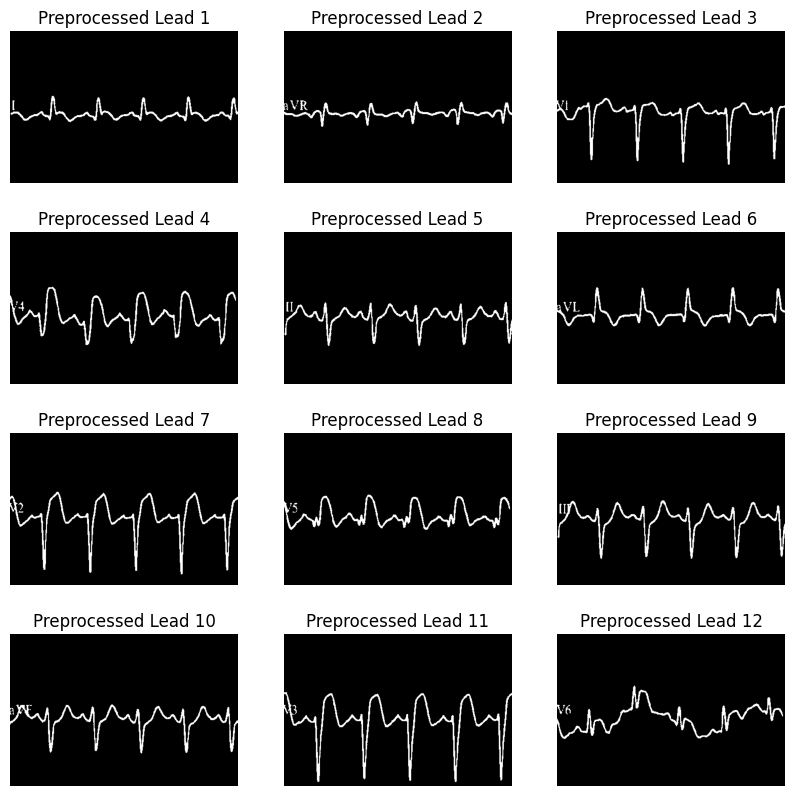

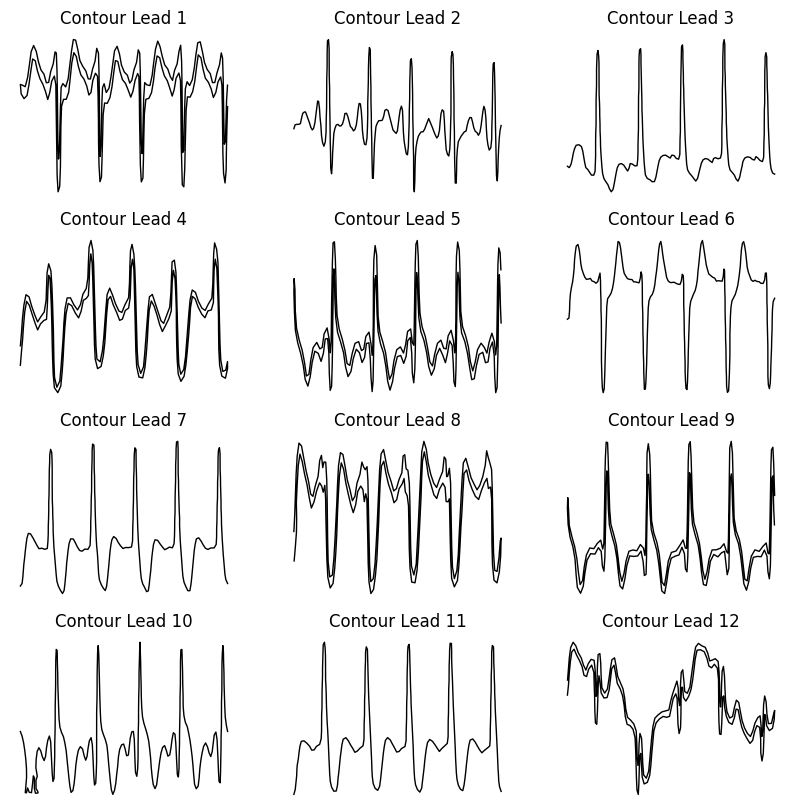

Extracted 1D Signals:
      0        1         2        3         4         5         6     \
0  0.70066  0.60181  0.462807  0.32996  0.312608  0.449422  0.597371   

       7         8        9     ...      3050      3051      3052      3053  \
0  0.745291  0.877867  0.91256  ...  0.817201  0.848839  0.896496  0.930594   

       3054  3055      3056      3057      3058      3059  
0  0.975512   1.0  0.965575  0.898874  0.821996  0.751164  

[1 rows x 3060 columns]


c:\Users\omkar\anaconda3\envs\ml_env\lib\site-packages\sklearn\base.py:380: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.0.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


AttributeError: 'PCA' object has no attribute 'predict'

In [ ]:
from skimage.io import imread
from skimage import color
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu, gaussian
from skimage.transform import resize
from numpy import asarray
from skimage.metrics import structural_similarity
from skimage import measure
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np
import os
from natsort import natsorted
import joblib

# Load image
uploaded_file = "test_image.jpg"  # Replace with the actual image path
image = imread(uploaded_file)
image_gray = color.rgb2gray(image)
image_gray = resize(image_gray, (1572, 2213))

# Load reference images for similarity check
image1 = imread("PMI(1).jpg")
image1 = color.rgb2gray(resize(image1, (1572, 2213)))

image2 = imread("HB(6).jpg")
image2 = color.rgb2gray(resize(image2, (1572, 2213)))

image3 = imread("Normal(1).jpg")
image3 = color.rgb2gray(resize(image3, (1572, 2213)))

image4 = imread("MI(1).jpg")
image4 = color.rgb2gray(resize(image4, (1572, 2213)))

similarity_score = max(structural_similarity(image_gray, img, data_range=img.max() - img.min()) for img in [image1, image2, image3, image4])

if similarity_score > 0.70:
    # Display original and grayscale image
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(image)
    ax[0].set_title("Uploaded ECG Image")
    ax[0].axis("off")
    ax[1].imshow(image_gray, cmap="gray")
    ax[1].set_title("Grayscale Image")
    ax[1].axis("off")
    plt.show()

    # Divide into leads
    Leads = [
        image[300:600, 150:643], image[300:600, 646:1135], image[300:600, 1140:1625], image[300:600, 1630:2125],
        image[600:900, 150:643], image[600:900, 646:1135], image[600:900, 1140:1625], image[600:900, 1630:2125],
        image[900:1200, 150:643], image[900:1200, 646:1135], image[900:1200, 1140:1625], image[900:1200, 1630:2125],
        image[1250:1480, 150:2125]
    ]

    # Display leads
    fig, ax = plt.subplots(4, 3, figsize=(10, 10))
    for i in range(12):
        ax[i // 3][i % 3].imshow(Leads[i])
        ax[i // 3][i % 3].axis("off")
        ax[i // 3][i % 3].set_title(f"Lead {i+1}")
    plt.show()

    # Preprocess leads
    fig, ax = plt.subplots(4, 3, figsize=(10, 10))
    for i in range(12):
        grayscale = color.rgb2gray(Leads[i])
        blurred_image = gaussian(grayscale, sigma=0.9)
        global_thresh = threshold_otsu(blurred_image)
        binary_global = blurred_image < global_thresh
        binary_global = resize(binary_global, (300, 450))

        ax[i // 3][i % 3].imshow(binary_global, cmap="gray")
        ax[i // 3][i % 3].axis("off")
        ax[i // 3][i % 3].set_title(f"Preprocessed Lead {i+1}")
    plt.show()

    # Extract signals
    fig, ax = plt.subplots(4, 3, figsize=(10, 10))
    for i in range(12):
        grayscale = color.rgb2gray(Leads[i])
        blurred_image = gaussian(grayscale, sigma=0.9)
        global_thresh = threshold_otsu(blurred_image)
        binary_global = blurred_image < global_thresh
        binary_global = resize(binary_global, (300, 450))

        contours = measure.find_contours(binary_global, 0.8)
        largest_contour = sorted(contours, key=lambda x: x.shape[0], reverse=True)[0]
        contour_resized = resize(largest_contour, (255, 2))

        ax[i // 3][i % 3].plot(contour_resized[:, 1], contour_resized[:, 0], linewidth=1, color="black")
        ax[i // 3][i % 3].axis("off")
        ax[i // 3][i % 3].set_title(f"Contour Lead {i+1}")

        # Save normalized signals
        scaler = MinMaxScaler()
        normalized_data = scaler.fit_transform(contour_resized)
        pd.DataFrame(normalized_data[:, 0]).T.to_csv(f"Scaled_1DLead_{i+1}.csv", index=False, mode="w")
    plt.show()

    # Combine all lead data
    combined_data = pd.read_csv("Scaled_1DLead_1.csv")
    for i in range(2, 13):
        lead_data = pd.read_csv(f"Scaled_1DLead_{i}.csv")
        combined_data = pd.concat([combined_data, lead_data], axis=1, ignore_index=True)

    print("Extracted 1D Signals:")
    print(combined_data)

    # Load ML model and predict
    loaded_model = joblib.load("finalmodel.pkl")
    result = loaded_model.predict(combined_data)

    if result[0] == 0:
        print("Your ECG corresponds to Myocardial Infarction.")
    elif result[0] == 1:
        print("Your ECG corresponds to Abnormal Heartbeat.")
    elif result[0] == 2:
        print("Your ECG is Normal.")
    elif result[0] == 3:
        print("Your ECG corresponds to History of Myocardial Infarction.")
else:
    print("Sorry, this image format is not currently supported. Please use an image similar to our sample input.")
